# MLP: Figure 1 and Table 2

This notebook **trains nine width-256 MLPs**: K20/K30/K40 at seeds 42/123/2026. Each uses only the 70% train split to update weights, with the 20% validation split selecting the best checkpoint. The fixed 10% local test is scored afterward. Input standardization is fitted on training rows only.

In [1]:
NAME="mlp"
from pathlib import Path
from datetime import datetime, timezone
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "splits/manifest.json").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from common import load_split
SEEDS = (42, 123, 2026)
RUN = ROOT / "results/notebook_reruns" / (NAME + "-" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
RUN.mkdir(parents=True)
print("Split seed 67; training seeds", SEEDS)
print("Fresh run directory:", RUN.relative_to(ROOT))

Split seed 67; training seeds (42, 123, 2026)
Fresh run directory: results/notebook_reruns/mlp-20261119T021103908070Z


## Figure 1: implemented architecture

The diagram is regenerated at the paper's 3.25-inch single-column width. Its labels use 10 pt Times text at native size; the visible neurons represent layers of 256 units.

MLP(
  (network): Sequential(
    (0): Linear(in_features=20, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)


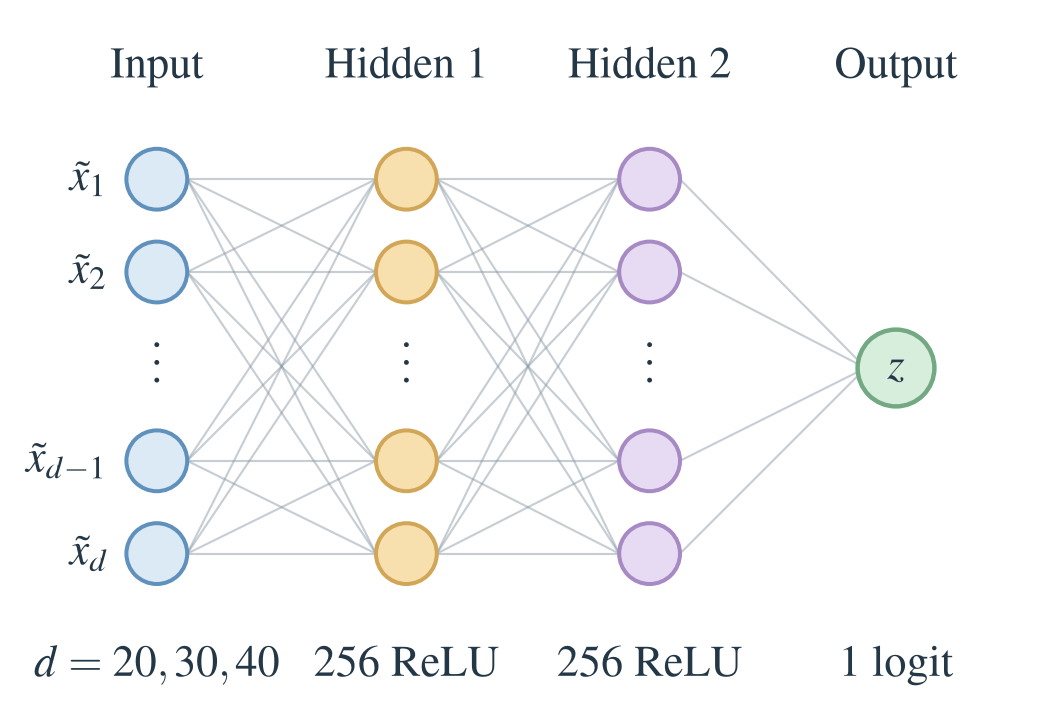

In [2]:
import runpy
from mlp.model import MLP
print(MLP(20,(256,256)))
runpy.run_path(str(ROOT/"paper/render_mlp_architecture.py"),run_name="__main__")
display(Image(filename=str(ROOT/"paper/figures/mlp_architecture.png")))

## Train on 70% and select checkpoints on 20% validation

In [3]:
from mlp.train import Config, fit, predict_checkpoint
import contextlib, io
checkpoints={}
for d in ("20","30","40"):
    x_train,y_train,x_val,y_val,_,_=load_split(d)
    for seed in SEEDS:
        target=RUN/f"K{d}_seed{seed}"
        config=Config(dataset=d,hidden_sizes=(256,256),seed=seed,purpose="width_comparison")
        with contextlib.redirect_stdout(io.StringIO()):
            result=fit(config,x_train,y_train,x_val,y_val,target)
        checkpoints[d,seed]=target/"best.pt"
        print(f'K{d} seed {seed}: best validation epoch {result["best_epoch"]}, validation accuracy {100*result["validation"]["accuracy"]:.2f}%')

K20 seed 42: best validation epoch 39, validation accuracy 91.38%


K20 seed 123: best validation epoch 67, validation accuracy 89.21%


K20 seed 2026: best validation epoch 48, validation accuracy 91.12%


K30 seed 42: best validation epoch 34, validation accuracy 91.27%


K30 seed 123: best validation epoch 101, validation accuracy 91.90%


K30 seed 2026: best validation epoch 49, validation accuracy 89.90%


K40 seed 42: best validation epoch 18, validation accuracy 93.19%


K40 seed 123: best validation epoch 20, validation accuracy 93.23%


K40 seed 2026: best validation epoch 16, validation accuracy 94.05%


## Evaluate the nine selected checkpoints on the fixed 10% local test

In [4]:
rows=[]
for d in ("20","30","40"):
    _,_,_,_,x_test,y_test=load_split(d)
    for seed in SEEDS:
        logits=predict_checkpoint(checkpoints[d,seed],x_test)
        pred=(logits>0).astype(np.int64)
        rows.append({"dataset":d,"seed":seed,"correct":int(np.sum(pred==y_test)),"test_size":len(y_test),"accuracy_pct":100*float(np.mean(pred==y_test))})
runs=pd.DataFrame(rows)
runs.to_csv(RUN/"local_test_runs.csv",index=False)
summary=runs.groupby("dataset")["accuracy_pct"].agg(mean="mean",sd="std")
row={"Method":"MLP (width 256)"}
for d in ("20","30","40"):
    row[f"K{d}"]=f'{summary.loc[d,"mean"]:.2f} ± {summary.loc[d,"sd"]:.2f}'
display(pd.DataFrame([row]).set_index("Method"))
print("Saved checkpoints and per-seed results in",RUN.relative_to(ROOT))

,K20,K30,K40
Method,,,
MLP (width 256),89.42 ± 0.80,91.87 ± 0.63,93.64 ± 0.69


Saved checkpoints and per-seed results in results/notebook_reruns/mlp-20261119T021103908070Z
